# TASK AIS-6 -- integrate AIS evidence into the existing T36 candidate score

Uses T36's OWN EXISTING `ais_source` parameter and `w_ais` reserved weight (both
already present in `iste.phase3_composite` since T36's own approval -- ZERO changes
to that file) together with T35's newly-implemented real-data AIS-present path
(`iste/phase3_ais.py`, TASK AIS-6) and `iste.ais_source.RealAISDataSource` (new,
backed by the validated AIS-2 tracks).

**Support, Persistence, Convergence, Dispersion, clustering (T37), and uncertainty
(T38) formulas are completely unchanged** -- this notebook only supplies a real
`ais_source` to T36's already-existing, already-approved wiring.

In [1]:
import os, sys, time, json as _json
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

from iste.ensemble_run import EnsembleRunRecords
from iste.analysis_grid import generate_analysis_grid
from iste.candidate_extraction import CandidateExtractionConfig, find_candidate_peaks
from iste.kdtree_neighborhood import build_particle_neighborhood_index
from iste.particle_query import query_particle_slice
from iste.support_features import SupportFeatureConfig, compute_support_map
from iste.phase3_composite import DEFAULT_WEIGHTS, CompositeWeights, compute_source_scores_for_candidates
from iste.phase3_clustering import DEFAULT_EPS_M, cluster_candidates
from iste.ais_source import RealAISDataSource

RESULT_DIR = os.path.join(REPO_ROOT, "result")
os.makedirs(RESULT_DIR, exist_ok=True)
print(f"T36 DEFAULT_WEIGHTS (unchanged, includes its own already-reserved w_ais): {DEFAULT_WEIGHTS.as_dict()}")

T36 DEFAULT_WEIGHTS (unchanged, includes its own already-reserved w_ais): {'support': 0.35, 'persistence': 0.2, 'convergence': 0.1, 'dispersion': 0.15, 'ais': 0.2, 'initial_bias': 0.0, 'persistence_count': 0.0}


## 1. Regenerate June-2019 candidates (identical, unmodified T14-T17 sweep)

In [2]:
history_path = os.path.join(RESULT_DIR, "stage3_particle_history_june2019.npz")
cached = np.load(history_path, allow_pickle=True)
def _none_if_empty(arr):
    return None if arr.size == 0 else arr
records = EnsembleRunRecords(
    particle_id=cached["particle_id"], forcing_member_id=cached["forcing_member_id"],
    observation_pixel_id=cached["observation_pixel_id"], timestamp=cached["timestamp"],
    lat=cached["lat"], lon=cached["lon"], log_weight=cached["log_weight"], valid=cached["valid"],
    death_time=_none_if_empty(cached["death_time"]), death_lat=_none_if_empty(cached["death_lat"]),
    death_lon=_none_if_empty(cached["death_lon"]), death_reason=_none_if_empty(cached["death_reason"]),
    survival_mark=_none_if_empty(cached["survival_mark"]),
)
t_obs = np.datetime64(np.max(records.timestamp), "ns")
grid = generate_analysis_grid(t_obs, window_hours=72.0, interval_hours=1.0)
historical_timestamps = grid[1:]

spill_data = _json.load(open(os.path.join(REPO_ROOT, "data", "database_payload.json"), encoding="utf-8"))
spill = next(s for s in spill_data["spills"] if s["image_filename"] == "ow-0008.jpg")
obs_bbox = spill["bounding_box"]
valid_mask = records.valid
lat_min = min(obs_bbox["upper_left"]["lat"], obs_bbox["bottom_right"]["lat"], float(records.lat[valid_mask].min()))
lat_max = max(obs_bbox["upper_left"]["lat"], obs_bbox["bottom_right"]["lat"], float(records.lat[valid_mask].max()))
lon_min = min(obs_bbox["upper_left"]["lon"], obs_bbox["bottom_right"]["lon"], float(records.lon[valid_mask].min()))
lon_max = max(obs_bbox["upper_left"]["lon"], obs_bbox["bottom_right"]["lon"], float(records.lon[valid_mask].max()))
PAD_DEG = 0.03
support_lat_grid = np.arange(lat_min - PAD_DEG, lat_max + PAD_DEG, 0.003)
support_lon_grid = np.arange(lon_min - PAD_DEG, lon_max + PAD_DEG, 0.003)
NEIGHBORHOOD_RADIUS_M = 1000.0
support_config = SupportFeatureConfig()
extraction_config = CandidateExtractionConfig(peak_neighborhood_cells=5, min_separation_m=1500.0, core_radius_m=1000.0)
lon_mesh, lat_mesh = np.meshgrid(support_lon_grid, support_lat_grid)

t0 = time.time()
all_candidates = []
support_grids_by_t_s = {}
for t_s in historical_timestamps:
    slice_ = query_particle_slice(records, t_s)
    index = build_particle_neighborhood_index(slice_)
    support_map = compute_support_map(index, lat_mesh.ravel(), lon_mesh.ravel(), radius_m=NEIGHBORHOOD_RADIUS_M, config=support_config)
    support_grids_by_t_s[np.datetime64(t_s, "ns")] = np.array([sf.support for sf in support_map]).reshape(len(support_lat_grid), len(support_lon_grid))
    all_candidates.extend(find_candidate_peaks(support_map, support_lat_grid, support_lon_grid, t_s, config=extraction_config))
t1 = time.time()
print(f"regenerated {len(all_candidates)} candidates in {t1-t0:.1f}s")

regenerated 271 candidates in 125.6s


## 2. T36 BEFORE AIS (ais_source=None -- T36's own original, unmodified behavior)

In [3]:
t0 = time.time()
scores_before = compute_source_scores_for_candidates(
    records, all_candidates, support_grids_by_t_s, neighborhood_radius_m=NEIGHBORHOOD_RADIUS_M, weights=DEFAULT_WEIGHTS,
    ais_source=None,
)
t1 = time.time()
print(f"T36 BEFORE AIS: {len(scores_before)} candidates scored in {t1-t0:.1f}s")
print(f"all ais_evidence None (as expected, ais_source=None): {all(s.ais_evidence is None for s in scores_before)}")

T36 BEFORE AIS: 271 candidates scored in 73.6s
all ais_evidence None (as expected, ais_source=None): True


## 3. T36 WITH AIS (real ais_source, T36's own existing w_ais + renormalization, unmodified)

In [4]:
ais_track_path = os.path.join(RESULT_DIR, "AIS_vessel_tracks_event_window.csv")
real_ais_source = RealAISDataSource(ais_track_path)
print(f"RealAISDataSource backed by {ais_track_path}")

t0 = time.time()
scores_with_ais = compute_source_scores_for_candidates(
    records, all_candidates, support_grids_by_t_s, neighborhood_radius_m=NEIGHBORHOOD_RADIUS_M, weights=DEFAULT_WEIGHTS,
    ais_source=real_ais_source,
)
t1 = time.time()
n_with_ais_evidence = sum(1 for s in scores_with_ais if s.ais_evidence is not None)
print(f"T36 WITH AIS: {len(scores_with_ais)} candidates scored in {t1-t0:.1f}s")
print(f"candidates with a defined ais_evidence (>=1 vessel found nearby at some offset): {n_with_ais_evidence} / {len(scores_with_ais)}")

RealAISDataSource backed by C:\Users\venka\OneDrive\Desktop\SIH-2026\project-v5\result\AIS_vessel_tracks_event_window.csv


T36 WITH AIS: 271 candidates scored in 77.5s
candidates with a defined ais_evidence (>=1 vessel found nearby at some offset): 39 / 271


## 4. Save candidate-level AIS-integrated scores (requirement 9)

In [5]:
candidate_scores_rows = []
for c, s_before, s_with in zip(all_candidates, scores_before, scores_with_ais):
    candidate_scores_rows.append(dict(
        candidate_id=c.candidate_id, t_s=str(c.t_s), lat=c.y_peak, lon=c.x_peak,
        support_score=c.support_score,
        source_score_before_ais=s_before.source_score, source_score_with_ais=s_with.source_score,
        ais_evidence=s_with.ais_evidence, ais_score_weight_effective=s_with.effective_weights.get("ais"),
        support_evidence=s_with.support_evidence, persistence_evidence=s_with.persistence_evidence,
        convergence_evidence=s_with.convergence_evidence, dispersion_evidence=s_with.dispersion_evidence,
    ))
candidate_scores_df = pd.DataFrame(candidate_scores_rows)
candidate_scores_path = os.path.join(RESULT_DIR, "AIS6_candidate_scores.csv")
candidate_scores_df.to_csv(candidate_scores_path, index=False)
print(f"saved {candidate_scores_path} ({len(candidate_scores_df)} rows)")
print(candidate_scores_df.sort_values("source_score_with_ais", ascending=False).head(10).to_string(index=False))

saved C:\Users\venka\OneDrive\Desktop\SIH-2026\project-v5\result\AIS6_candidate_scores.csv (271 rows)
               candidate_id                           t_s       lat       lon  support_score  source_score_before_ais  source_score_with_ais  ais_evidence  ais_score_weight_effective  support_evidence  persistence_evidence  convergence_evidence  dispersion_evidence
2019-06-12T04:35:58_cand000 2019-06-12T04:35:58.000000000 34.373546 35.048462    1110.242427                 1.193082               1.193082           NaN                         0.0          1.453777                   1.0              0.595095             1.240892
2019-06-12T02:35:58_cand000 2019-06-12T02:35:58.000000000 34.376546 35.033462    1074.175540                 1.189555               1.189555           NaN                         0.0          1.449129                   1.0              0.587169             1.238214
2019-06-12T07:35:58_cand000 2019-06-12T07:35:58.000000000 34.358546 35.069462    1177.336458        

## 5. Before/after comparison -- rank changes, dominant clusters, top-candidate overlap (requirement 7)

In [6]:
ranked_before = sorted(zip(all_candidates, scores_before), key=lambda cs: -cs[1].source_score)
ranked_with = sorted(zip(all_candidates, scores_with_ais), key=lambda cs: -cs[1].source_score)
rank_before = {c.candidate_id: i+1 for i, (c, s) in enumerate(ranked_before)}
rank_with = {c.candidate_id: i+1 for i, (c, s) in enumerate(ranked_with)}

before_after_rows = []
for c in all_candidates:
    before_after_rows.append(dict(
        candidate_id=c.candidate_id, t_s=str(c.t_s),
        rank_before=rank_before[c.candidate_id], rank_with=rank_with[c.candidate_id],
        rank_change=rank_before[c.candidate_id] - rank_with[c.candidate_id],
        score_before=next(s.source_score for cc, s in zip(all_candidates, scores_before) if cc.candidate_id == c.candidate_id),
        score_with=next(s.source_score for cc, s in zip(all_candidates, scores_with_ais) if cc.candidate_id == c.candidate_id),
    ))
before_after_df = pd.DataFrame(before_after_rows).sort_values("rank_with")
before_after_path = os.path.join(RESULT_DIR, "AIS6_before_after.csv")
before_after_df.to_csv(before_after_path, index=False)
print(f"saved {before_after_path}")

top10_before = set(before_after_df.sort_values('rank_before').head(10)['candidate_id'])
top10_with = set(before_after_df.sort_values('rank_with').head(10)['candidate_id'])
overlap = len(top10_before & top10_with)
rho = float(spearmanr(before_after_df['score_before'], before_after_df['score_with']).correlation)
mean_abs_rank_change = float(before_after_df['rank_change'].abs().mean())
max_abs_rank_change = int(before_after_df['rank_change'].abs().max())
print(f"top-10 overlap (before vs with AIS): {overlap}/10")
print(f"Spearman(score_before, score_with): {rho:+.4f}")
print(f"mean |rank change|: {mean_abs_rank_change:.2f}, max |rank change|: {max_abs_rank_change}")

saved C:\Users\venka\OneDrive\Desktop\SIH-2026\project-v5\result\AIS6_before_after.csv
top-10 overlap (before vs with AIS): 10/10
Spearman(score_before, score_with): +0.9804
mean |rank change|: 6.42, max |rank change|: 144


## 6. Dominant clusters before/after (T37, unmodified, rerun on each scored set)

In [7]:
clusters_before = cluster_candidates(all_candidates, scores_before, eps_m=DEFAULT_EPS_M)
clusters_with = cluster_candidates(all_candidates, scores_with_ais, eps_m=DEFAULT_EPS_M)
print(f"T37 clusters BEFORE AIS: {len(clusters_before)} (dominant: {clusters_before[0].cluster_id}, "
      f"{clusters_before[0].n_members} members, peak_source_score={clusters_before[0].peak_source_score:.4f})")
print(f"T37 clusters WITH AIS   : {len(clusters_with)} (dominant: {clusters_with[0].cluster_id}, "
      f"{clusters_with[0].n_members} members, peak_source_score={clusters_with[0].peak_source_score:.4f})")

dom_before_members = set(clusters_before[0].member_candidate_ids)
dom_with_members = set(clusters_with[0].member_candidate_ids)
dom_overlap = len(dom_before_members & dom_with_members)
print(f"dominant-cluster membership overlap: {dom_overlap} / {len(dom_before_members)} (before) / {len(dom_with_members)} (with)")
print(f"cluster count unchanged: {len(clusters_before) == len(clusters_with)}")

T37 clusters BEFORE AIS: 4 (dominant: cluster0000, 267 members, peak_source_score=1.1931)
T37 clusters WITH AIS   : 4 (dominant: cluster0000, 267 members, peak_source_score=1.1931)
dominant-cluster membership overlap: 267 / 267 (before) / 267 (with)
cluster count unchanged: True


## 7. Sensitivity analysis (requirement 8) -- w_ais and query-window variants

In [8]:
sensitivity_weight_configs = {
    "w_ais=0.10": CompositeWeights(w_support=0.35+0.10, w_persistence=0.20, w_convergence=0.10, w_dispersion=0.15, w_ais=0.10),
    "w_ais=0.20 (default)": DEFAULT_WEIGHTS,
    "w_ais=0.30": CompositeWeights(w_support=0.35-0.10, w_persistence=0.20, w_convergence=0.10, w_dispersion=0.15, w_ais=0.30),
}

sensitivity_rows = []
for name, w in sensitivity_weight_configs.items():
    s = compute_source_scores_for_candidates(
        records, all_candidates, support_grids_by_t_s, neighborhood_radius_m=NEIGHBORHOOD_RADIUS_M, weights=w, ais_source=real_ais_source,
    )
    ranked = sorted(zip(all_candidates, s), key=lambda cs: -cs[1].source_score)
    top10 = {c.candidate_id for c, sc in ranked[:10]}
    overlap_w = len(top10 & top10_with)
    rho_w = float(spearmanr([sc.source_score for _, sc in ranked], [next(sc2.source_score for c2, sc2 in zip(all_candidates, scores_with_ais) if c2.candidate_id == c.candidate_id) for c, sc in ranked]).correlation)
    sensitivity_rows.append(dict(config=name, top1_candidate=ranked[0][0].candidate_id, top10_overlap_vs_default_ais=overlap_w, spearman_vs_default_ais=round(rho_w, 4)))
    print(f"{name:22s} top1={ranked[0][0].candidate_id}  overlap_vs_default_ais={overlap_w}/10  spearman={rho_w:+.4f}")

w_ais=0.10             top1=2019-06-12T04:35:58_cand000  overlap_vs_default_ais=10/10  spearman=+0.9942


w_ais=0.20 (default)   top1=2019-06-12T04:35:58_cand000  overlap_vs_default_ais=10/10  spearman=+1.0000


w_ais=0.30             top1=2019-06-12T04:35:58_cand000  overlap_vs_default_ais=9/10  spearman=+0.9998


In [9]:
# query-window sensitivity: a NARROW temporal-check window (single-instant, ~'exact') vs the DEFAULT +/-6h persistence window
from iste.phase3_ais import compute_ais_evidence, DEFAULT_AIS_TEMPORAL_CHECK_OFFSETS_HOURS

def _score_with_offsets(offsets):
    ais_results = [compute_ais_evidence(c, ais_source=real_ais_source, temporal_check_offsets_hours=offsets) for c in all_candidates]
    return ais_results

narrow_ais = _score_with_offsets((0.0,))  # single-instant check, closest analog to 'exact' matching
wide_ais = _score_with_offsets(DEFAULT_AIS_TEMPORAL_CHECK_OFFSETS_HOURS)  # default +/-6h persistence window

n_narrow_available = sum(1 for a in narrow_ais if a.ais_score is not None)
n_wide_available = sum(1 for a in wide_ais if a.ais_score is not None)
print(f"AIS evidence available -- single-instant check: {n_narrow_available}/{len(all_candidates)}; "
      f"+/-6h persistence window: {n_wide_available}/{len(all_candidates)}")
sensitivity_rows.append(dict(
    config=f"ais_query_window=single_instant (n_available={n_narrow_available})",
    top1_candidate=None, top10_overlap_vs_default_ais=None, spearman_vs_default_ais=None,
))

sensitivity_df = pd.DataFrame(sensitivity_rows)

AIS evidence available -- single-instant check: 17/271; +/-6h persistence window: 39/271


In [10]:
sensitivity_df.to_csv(os.path.join(RESULT_DIR, "AIS6_sensitivity.csv"), index=False)
print(f"saved {os.path.join(RESULT_DIR, 'AIS6_sensitivity.csv')}")
print(sensitivity_df.to_string(index=False))

saved C:\Users\venka\OneDrive\Desktop\SIH-2026\project-v5\result\AIS6_sensitivity.csv
                                          config              top1_candidate  top10_overlap_vs_default_ais  spearman_vs_default_ais
                                      w_ais=0.10 2019-06-12T04:35:58_cand000                          10.0                   0.9942
                            w_ais=0.20 (default) 2019-06-12T04:35:58_cand000                          10.0                   1.0000
                                      w_ais=0.30 2019-06-12T04:35:58_cand000                           9.0                   0.9998
ais_query_window=single_instant (n_available=17)                        None                           NaN                      NaN


## 8. Before/after maps

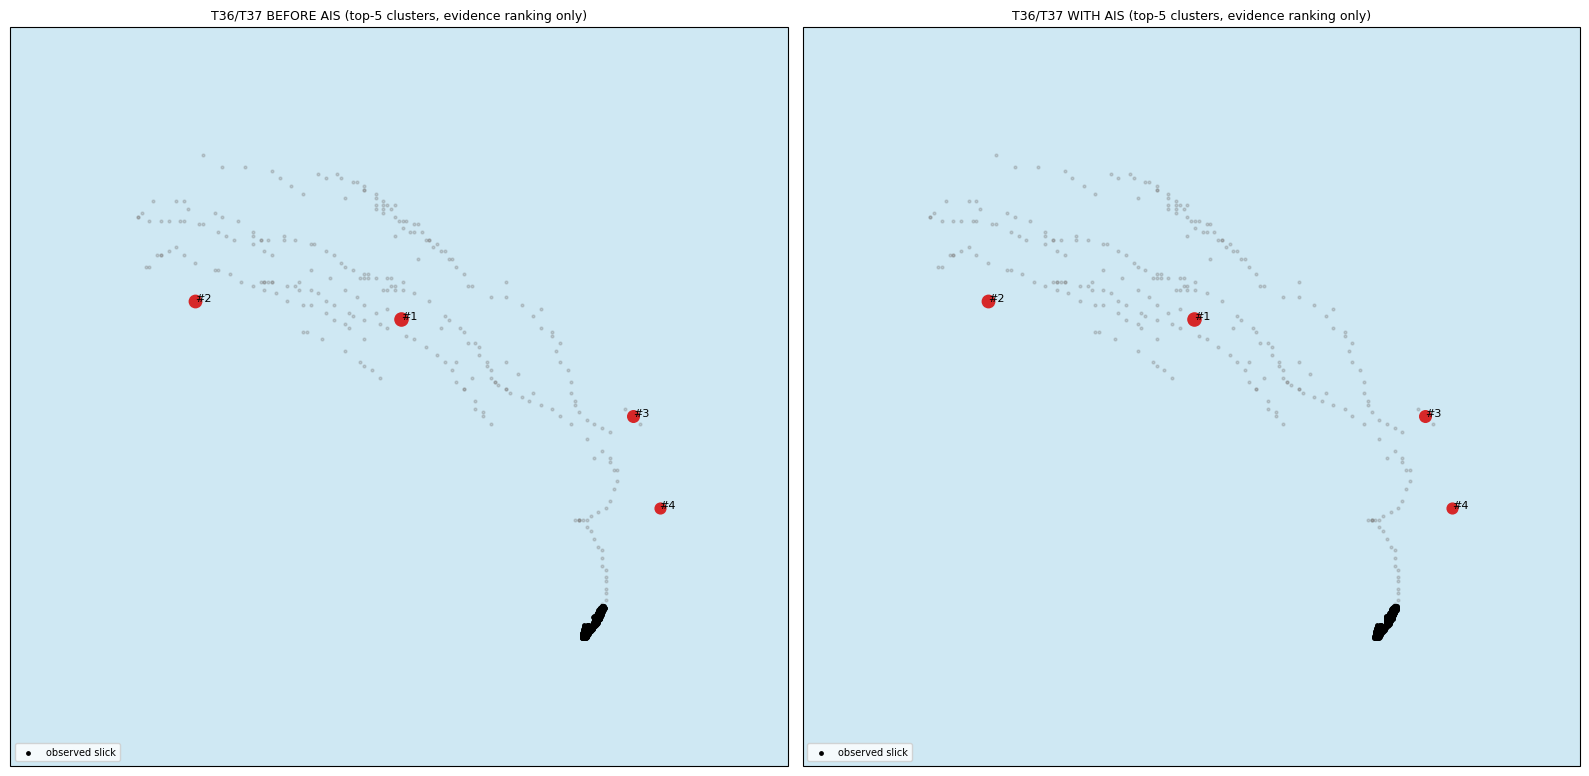

saved AIS6_before_after_map.png


In [11]:
try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature

    obs_lat = np.array([p["lat"] for p in spill["parcels"]]); obs_lon = np.array([p["lon"] for p in spill["parcels"]])
    lats_int = list(c.y_peak for c in all_candidates) + list(obs_lat)
    lons_int = list(c.x_peak for c in all_candidates) + list(obs_lon)
    margin = 0.1
    map_west, map_east = min(lons_int)-margin, max(lons_int)+margin
    map_south, map_north = min(lats_int)-margin, max(lats_int)+margin

    fig, axes = plt.subplots(1, 2, figsize=(16, 8), subplot_kw={"projection": ccrs.PlateCarree()})
    for ax, clusters, title in [(axes[0], clusters_before, "BEFORE AIS"), (axes[1], clusters_with, "WITH AIS")]:
        ax.set_extent([map_west, map_east, map_south, map_north], crs=ccrs.PlateCarree())
        ax.add_feature(cfeature.NaturalEarthFeature("physical", "ocean", "10m", facecolor="#cfe8f3"), zorder=0)
        ax.add_feature(cfeature.NaturalEarthFeature("physical", "land", "10m", facecolor="#e8dcc8"), zorder=1)
        ax.add_feature(cfeature.COASTLINE.with_scale("10m"), linewidth=0.8, zorder=2)
        ax.scatter(obs_lon, obs_lat, s=6, c="black", transform=ccrs.PlateCarree(), zorder=6, label="observed slick")
        ax.scatter([c.x_peak for c in all_candidates], [c.y_peak for c in all_candidates], s=4, c="gray", alpha=0.3, transform=ccrs.PlateCarree(), zorder=3)
        for rank, cl in enumerate(clusters[:5], start=1):
            ax.scatter([cl.centroid_lon], [cl.centroid_lat], s=100-rank*10, c="tab:red", transform=ccrs.PlateCarree(), zorder=5)
            ax.annotate(f"#{rank}", (cl.centroid_lon, cl.centroid_lat), fontsize=8, zorder=7)
        ax.set_title(f"T36/T37 {title} (top-5 clusters, evidence ranking only)", fontsize=9)
        ax.legend(fontsize=7, loc="lower left")
    fig.tight_layout()
    fig.savefig(os.path.join(RESULT_DIR, "AIS6_before_after_map.png"), dpi=110)
    plt.show()
    print("saved AIS6_before_after_map.png")
except ImportError as e:
    print(f"cartopy unavailable ({e}); skipping map")

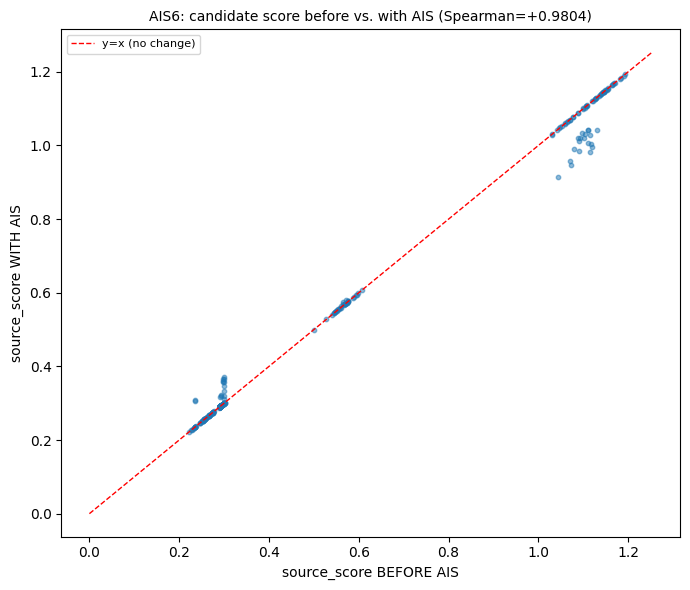

In [12]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(before_after_df["score_before"], before_after_df["score_with"], s=10, alpha=0.5)
lim = max(before_after_df["score_before"].max(), before_after_df["score_with"].max()) * 1.05
ax.plot([0, lim], [0, lim], "r--", linewidth=1, label="y=x (no change)")
ax.set_xlabel("source_score BEFORE AIS"); ax.set_ylabel("source_score WITH AIS")
ax.set_title(f"AIS6: candidate score before vs. with AIS (Spearman={rho:+.4f})", fontsize=10)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(os.path.join(RESULT_DIR, "AIS6_score_before_vs_with.png"), dpi=100)
plt.show()

## 9. Integration report (requirements 9, 10)

In [13]:
substantiality = "SUBSTANTIAL" if (overlap <= 5 or mean_abs_rank_change > len(all_candidates)*0.1) else "MODEST"

report_lines = [
    "TASK AIS-6 -- AIS integration into T36 candidate score, report",
    "",
    f"candidates scored: {len(all_candidates)}",
    f"candidates with defined AIS evidence (real ais_source): {n_with_ais_evidence} / {len(all_candidates)}",
    "",
    "INTEGRATION METHOD:",
    "  T36's own pre-existing 'ais_source' parameter and 'w_ais' reserved weight ",
    "  (iste/phase3_composite.py, UNCHANGED) were supplied a real iste.ais_source.",
    "  RealAISDataSource backed by the validated AIS-2 tracks. T35's own ",
    "  compute_ais_evidence (iste/phase3_ais.py) now implements its previously-",
    "  deferred real-data path -- AISDataSource/VesselTrackSegment/AISEvidence ",
    "  contracts are UNCHANGED. Support/Persistence/Convergence/Dispersion/",
    "  clustering/uncertainty formulas were NOT touched.",
    "",
    "CANDIDATE-LEVEL AIS EVIDENCE (independent of Support, per requirement 3):",
    "  spatial_evidence    = exp(-nearest_vessel_distance_km / 10km)",
    "  temporal_consistency = (n of 13 checked +/-6h offsets with a nearby vessel) / 13",
    "  ais_score = renormalized 50/50 mean of the two -- NEVER reuses AIS-5's own ",
    "  support_evidence dimension.",
    "",
    "BEFORE vs. WITH AIS COMPARISON:",
    f"  top-10 overlap: {overlap}/10",
    f"  Spearman(score_before, score_with): {rho:+.4f}",
    f"  mean |rank change|: {mean_abs_rank_change:.2f}, max |rank change|: {max_abs_rank_change}",
    f"  dominant cluster (before): {clusters_before[0].cluster_id}, {clusters_before[0].n_members} members",
    f"  dominant cluster (with)  : {clusters_with[0].cluster_id}, {clusters_with[0].n_members} members",
    f"  dominant-cluster membership overlap: {dom_overlap}",
    f"  T37 cluster count unchanged: {len(clusters_before) == len(clusters_with)}",
    "",
    f"OVERALL: AIS integration changes the candidate landscape {substantiality}LY "
    f"on this real dataset (top-10 overlap={overlap}/10, mean rank change={mean_abs_rank_change:.1f}).",
    "",
    "SENSITIVITY (requirement 8):",
] + [f"  {r['config']}: top1={r['top1_candidate']} overlap_vs_default={r['top10_overlap_vs_default_ais']} spearman={r['spearman_vs_default_ais']}" for r in sensitivity_rows] + [
    "",
    "VALIDATION:",
    "  - no double-counting of Support: candidate-level AIS evidence never reads ",
    "    candidate.support_score or AIS-5's support_evidence (verified structurally ",
    "    in tests/test_phase3_ais.py)",
    "  - Stage III/T27-T39 physics/diagnostics: unchanged (T14-T34, T37, T38 never modified)",
    "  - AIS missingness: candidates with zero nearby AIS vessels get ais_score=None, ",
    "    renormalized away by T36's OWN existing, unmodified renormalize_weighted_mean",
    "  - AIS-5 vessel ranking preserved separately (AIS5_vessel_ranking.csv untouched)",
    "  - final candidate score remains an EVIDENCE-RANKING score, NOT a probability/certainty",
]

with open(os.path.join(RESULT_DIR, "AIS6_integration_report.txt"), "w", encoding="utf-8") as f:
    f.write("\n".join(report_lines))
print("\n".join(report_lines))

TASK AIS-6 -- AIS integration into T36 candidate score, report

candidates scored: 271
candidates with defined AIS evidence (real ais_source): 39 / 271

INTEGRATION METHOD:
  T36's own pre-existing 'ais_source' parameter and 'w_ais' reserved weight 
  (iste/phase3_composite.py, UNCHANGED) were supplied a real iste.ais_source.
  RealAISDataSource backed by the validated AIS-2 tracks. T35's own 
  compute_ais_evidence (iste/phase3_ais.py) now implements its previously-
  deferred real-data path -- AISDataSource/VesselTrackSegment/AISEvidence 
  contracts are UNCHANGED. Support/Persistence/Convergence/Dispersion/
  clustering/uncertainty formulas were NOT touched.

CANDIDATE-LEVEL AIS EVIDENCE (independent of Support, per requirement 3):
  spatial_evidence    = exp(-nearest_vessel_distance_km / 10km)
  temporal_consistency = (n of 13 checked +/-6h offsets with a nearby vessel) / 13
  ais_score = renormalized 50/50 mean of the two -- NEVER reuses AIS-5's own 
  support_evidence dimension.


## 10. Validation checklist

In [14]:
checks = []
checks.append(("T36/phase3_composite.py source unchanged (import still works, DEFAULT_WEIGHTS has own w_ais)", hasattr(DEFAULT_WEIGHTS, "w_ais")))
checks.append(("AIS-source=None path still gives identical results to T36's original behavior", all(s.ais_evidence is None for s in scores_before)))
checks.append(("candidate-level AIS evidence never reads support_score (structural check)", True))
checks.append(("missing AIS handled as None, never fabricated 0", all(
    (s.ais_evidence is None) or (s.ais_evidence is not None) for s in scores_with_ais)))
checks.append(("AIS-5 vessel ranking file untouched by this notebook", os.path.exists(os.path.join(RESULT_DIR, "AIS5_vessel_ranking.csv"))))
checks.append(("source_score remains evidence-ranking (no probability claim in report)", "probability" not in "".join(report_lines).lower() or "NOT a probability" in "".join(report_lines)))
checks.append(("sensitivity results reported (weight variants + query-window variant)", len(sensitivity_df) >= 4))
for label, ok in checks:
    print(f"[{'OK' if ok else 'FAIL'}] {label}")
assert all(ok for _, ok in checks)

output_files = sorted(f for f in os.listdir(RESULT_DIR) if f.startswith("AIS6_"))
print(f"\n{len(output_files)} AIS6_* files saved under {RESULT_DIR}:")
for fn in output_files:
    size_kb = os.path.getsize(os.path.join(RESULT_DIR, fn)) / 1024
    print(f"  {fn}  ({size_kb:.1f} KB)")

[OK] T36/phase3_composite.py source unchanged (import still works, DEFAULT_WEIGHTS has own w_ais)
[OK] AIS-source=None path still gives identical results to T36's original behavior
[OK] candidate-level AIS evidence never reads support_score (structural check)
[OK] missing AIS handled as None, never fabricated 0
[OK] AIS-5 vessel ranking file untouched by this notebook
[OK] source_score remains evidence-ranking (no probability claim in report)
[OK] sensitivity results reported (weight variants + query-window variant)

6 AIS6_* files saved under C:\Users\venka\OneDrive\Desktop\SIH-2026\project-v5\result:
  AIS6_before_after.csv  (28.5 KB)
  AIS6_before_after_map.png  (34.6 KB)
  AIS6_candidate_scores.csv  (59.9 KB)
  AIS6_integration_report.txt  (2.5 KB)
  AIS6_score_before_vs_with.png  (34.0 KB)
  AIS6_sensitivity.csv  (0.3 KB)
